# Pricing and hedging a European put

George Dharma

Can a short-option desk reduce turnover while keeping the size of poor hedge outcomes close to daily rebalancing?

A 2.5-point change in delta triggers about 84 stock trades per path, down from 249 when rebalancing daily. In the matched-volatility simulation it saves $212 of execution cost while the mean of the worst 5% of losses grows by $32.

## Read or reproduce the work

The saved tables and chart can be read immediately. To execute the cells, open this notebook from the extracted Python project. Set `rebuild = True` below to regenerate the outputs from the supplied inputs.

In [1]:
from pathlib import Path
import subprocess
import sys
import pandas as pd
from IPython.display import Image

# If the notebook was downloaded separately, unpack the Python package alongside it.
here = Path.cwd()
candidates = [here, here.parent, here / "George_Dharma_10_Options_Python", here.parent / "George_Dharma_10_Options_Python"]
root = next((p for p in candidates if (p / "run_analysis.py").exists() and (p / "options").is_dir()), None)
if root is None:
    raise FileNotFoundError("Extract the complete research package and open this notebook from its project folder.")
sys.path.insert(0, str(root))
output = root / "outputs"
rebuild = False
if rebuild or not (output / "band_summary.csv").exists() or not (output / "delta_band_tradeoff.png").exists():
    subprocess.run([sys.executable, str(root / "run_analysis.py")], cwd=root, check=True)
print("Project data and output files are ready.")

Project data and output files are ready.


## Price the reference contract

The workbook and this code use a $36 spot, $40 strike, a one-year maturity, 6% interest and 20% implied volatility. The position is short 10,000 units. The negative share trade offsets the positive delta of the short puts.

In [2]:
import json
from options.engine import Option, price, delta
assumptions = json.loads((root / "data/assumptions.json").read_text(encoding="utf-8"))
option = Option(**assumptions["option"])
units = assumptions["simulation"]["units"]
print(f"Option price: ${price(option):.6f} per unit")
print(f"Required share position: {delta(option, option.spot, option.years) * units:,.2f}")
pd.read_csv(output / "quotes.csv").round(5)

Option price: $3.844308 per unit
Required share position: -5,504.52


,side,premium,implied_volatility,repriced
0,Bid,3.80,0.19689,3.80
1,Mid,3.85,0.20040,3.85
2,Ask,3.90,0.20391,3.90


## Portfolio results at a glance

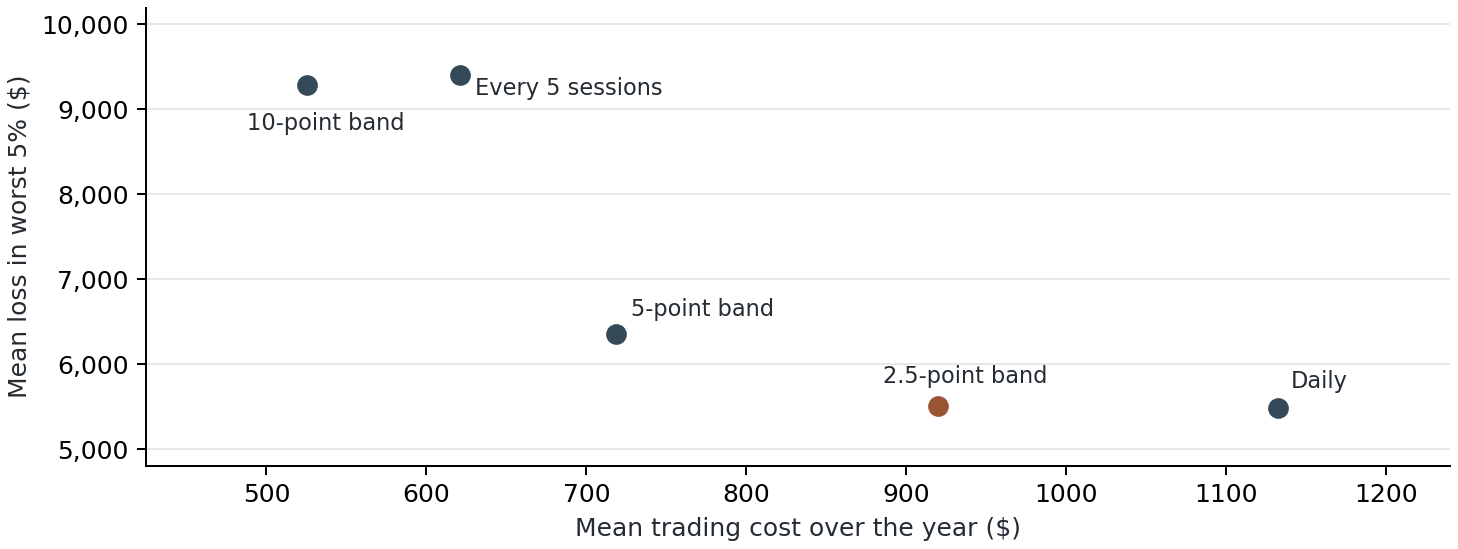

In [3]:
Image(filename=str(output / "delta_band_tradeoff.png"), width=810)

## Read the matched-path execution results

Each policy sees the same 30,000 stock paths in a scenario. The worst 5% mean is an average of terminal cash P&L in the 1,500 worst paths for that policy.

In [4]:
policies = pd.read_csv(output / "band_summary.csv")
columns = ["policy", "trade_count", "cash_cost", "mean", "tail_mean"]
policies.loc[policies.case.eq("Base"), columns].round(1)

,policy,trade_count,cash_cost,mean,tail_mean
0,Daily,249.3,1132.4,-1148.9,-5477.5
1,Every 5 sessions,51.4,621.2,-611.5,-9402.3
2,2.5-point band,83.5,919.9,-929.8,-5509.2
3,5-point band,39.2,718.5,-724.4,-6355.0
4,10-point band,15.5,525.6,-526.9,-9288.0


## See what changes under jumps or higher volatility

Each case uses the same implied volatility when deciding the hedge. Read the numbers below as terminal dollar P&L for 100 short contracts.

In [5]:
tails = policies.pivot(index="policy", columns="case", values="tail_mean")
paired = pd.read_csv(output / "band_differences.csv")
narrow = paired[(paired.case == "Base") & (paired.policy == "2.5-point band")].iloc[0]
print(f"Mean P&L improvement vs daily: ${narrow.paired_mean:,.0f}")
print(f"Paired 95% Monte Carlo interval: ${narrow.ci_low:,.0f} to ${narrow.ci_high:,.0f}")
tails[["Base", "Higher volatility", "Jumps"]].round(0)

Mean P&L improvement vs daily: $219
Paired 95% Monte Carlo interval: $209 to $229


case,Base,Higher volatility,Jumps
policy,,,
10-point band,-9288.0,-36224.0,-55948.0
2.5-point band,-5509.0,-34979.0,-57059.0
5-point band,-6355.0,-34990.0,-56547.0
Daily,-5477.0,-35212.0,-57433.0
Every 5 sessions,-9402.0,-39895.0,-57805.0


## Source

QuantLib, European equity-option example. The contract inputs come from the example. Coverage, execution costs, simulated market paths and trigger rules are specific to this study.

[Open the original source](https://github.com/lballabio/QuantLib/blob/e4090768195f9c5b0bf8a6d0cb6802238342c50d/Examples/EquityOption/EquityOption.cpp)